# Лабораторная работа №3. Кластерный анализ методом DBSCAN

**Цель работы:** провести кластеризацию данных методом DBSCAN, подобрать параметры алгоритма и проанализировать полученные кластеры.

## 1. Загрузка и проверка данных

Используется набор данных «Леденцы», содержащий результаты опроса потребителей. Каждое наблюдение включает оценки 11 утверждений (V1–V11), связанных с мотивами потребления леденцов.

Загрузим данные, проверим их размер, типы признаков и наличие пропусков.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Леденцы.dat', sep=';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [2]:
#проверка
print('Размер данных:', df.shape)
df.info()

Размер данных: (338, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


In [3]:
#пропуски
df.isnull().sum()

,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


В наборе данных 338 наблюдений и 11 числовых признаков. Все столбцы имеют тип int64, пропущенные значения отсутствуют. Данные готовы к дальнейшему анализу.

## 2. Разведочный анализ данных (EDA)

### 2.1. Описательная статистика

Рассчитаем основные статистические характеристики признаков: среднее значение, стандартное отклонение, минимум, максимум и квартили.

In [4]:
df.describe().round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00
mean,3.54,3.53,3.52,3.41,3.21,3.20,3.25,3.29,3.60,3.55,3.57
std,0.96,0.96,0.99,0.99,0.87,0.87,0.84,0.82,0.97,0.93,0.94
min,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00
25%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
50%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
75%,5.00,5.00,5.00,4.00,3.00,3.00,3.00,3.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


Все признаки имеют одну шкалу оценок. Средние значения близки друг к другу, поэтому явного преобладания отдельных признаков по общему среднему не наблюдается.

### 2.2. Распределение оценок

Посмотрим, как распределяются оценки по каждому признаку. Для сравнения используем столбчатую диаграмму с долями оценок.

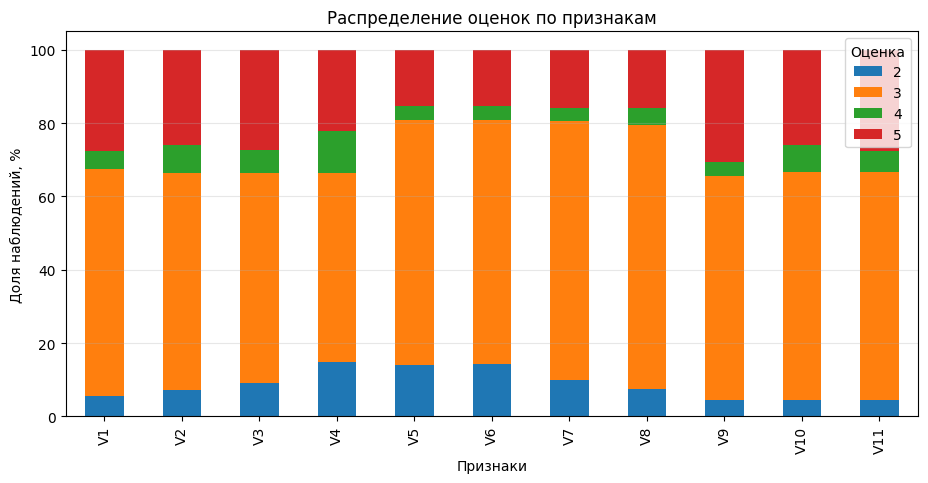

In [5]:
freq = pd.DataFrame({
    col: df[col].value_counts(normalize=True)
    for col in df.columns
}).fillna(0).T * 100

freq = freq.reindex(columns=sorted(freq.columns))

freq.plot(kind='bar', stacked=True, figsize=(11, 5))

plt.xlabel('Признаки')
plt.ylabel('Доля наблюдений, %')
plt.title('Распределение оценок по признакам')
plt.legend(title='Оценка')
plt.grid(axis='y', alpha=0.3)
plt.show()

По всем признакам чаще всего встречается оценка 3. Оценки 5 наиболее распространены среди V1–V4 и V9–V11. Распределения признаков различаются, хотя их средние значения близки.

### 2.3. Корреляция признаков

Рассчитаем коэффициенты корреляции Пирсона между признаками. Тепловая карта позволит определить, какие оценки изменяются согласованно.

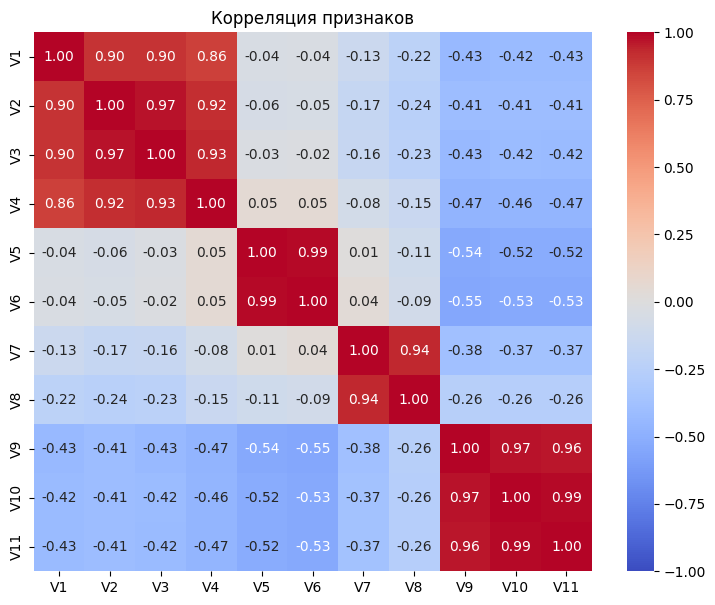

In [6]:
corr = df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, center=0)

plt.title('Корреляция признаков')
plt.show()

Здесь положительная корреляция означает, что высокие оценки одного признака чаще сопровождаются высокими оценками другого. Отрицательная — что оценки изменяются в противоположных направлениях.

Выделяются четыре группы признаков с сильной положительной корреляцией: V1–V4, V5–V6, V7–V8 и V9–V11. Внутри этих групп коэффициенты достигают 0,94–0,99.

Между некоторыми группами наблюдается отрицательная корреляция. Это указывает на различия в оценках потребителей.

### 2.4. Повторяющиеся наблюдения
Для DBSCAN этот этап особенно важен. Если несколько человек дали одинаковые ответы, их точки совпадают в 11-мерном пространстве и расстояние между ними равно нулю.

Всего наблюдений: 338
Уникальных наборов оценок: 45
Повторных строк: 293


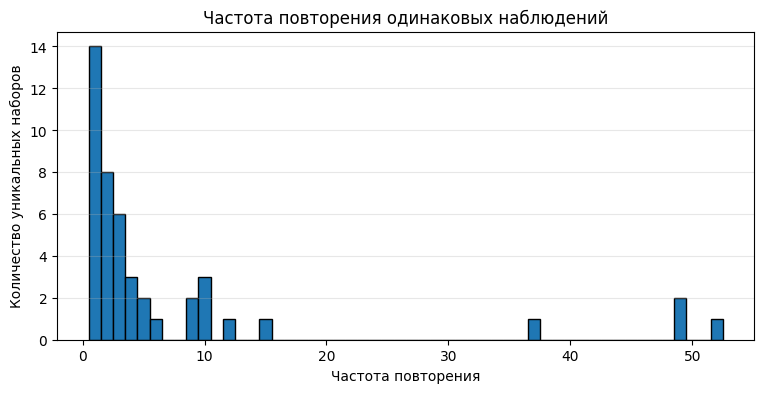

In [7]:
counts = df.value_counts()

print('Всего наблюдений:', len(df))
print('Уникальных наборов оценок:', len(counts))
print('Повторных строк:', df.duplicated().sum())

plt.figure(figsize=(9, 4))
plt.hist(counts.values, bins=range(1, counts.max() + 2),
         edgecolor='black', align='left')

plt.xlabel('Частота повторения')
plt.ylabel('Количество уникальных наборов')
plt.title('Частота повторения одинаковых наблюдений')
plt.grid(axis='y', alpha=0.3)
plt.show()

Из 338 наблюдений только 45 имеют уникальные комбинации оценок. Остальные 293 строки повторяют уже встречавшиеся наборы. Некоторые комбинации встречаются почти 50 раз.

Повторяющиеся наблюдения оставляем, поскольку они влияют на плотность точек при кластеризации DBSCAN.

### 2.5. Распределение расстояний

Рассчитаем евклидовы расстояния между всеми парами наблюдений. По гистограмме оценим, какие расстояния встречаются чаще.

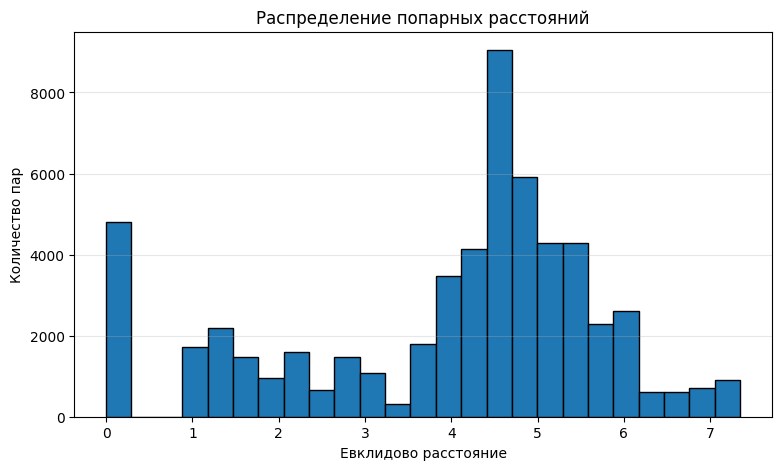

Доля пар с нулевым расстоянием: 8.43 %


In [8]:
from scipy.spatial.distance import pdist

dist = pdist(df, metric='euclidean')

plt.figure(figsize=(9, 5))
plt.hist(dist, bins=25, edgecolor='black')

plt.xlabel('Евклидово расстояние')
plt.ylabel('Количество пар')
plt.title('Распределение попарных расстояний')
plt.grid(axis='y', alpha=0.3)
plt.show()

print('Доля пар с нулевым расстоянием:',
      round((dist == 0).mean() * 100, 2), '%')

Нулевое расстояние имеют 8,43% пар наблюдений, что связано с повторяющимися наборами оценок. Большинство ненулевых расстояний находится примерно в диапазоне от 4 до 6.

Это показывает, что в данных одновременно есть совпадающие и заметно различающиеся наблюдения.

## 3. Подбор параметров DBSCAN

Для кластеризации используем евклидову метрику. Метод DBSCAN имеет два основных параметра:

- `eps` — радиус окрестности точки;
- `min_samples` — минимальное число точек в окрестности, включая саму точку.

### 3.1. Расстояния до ближайших соседей

Для предварительного выбора eps построим графики расстояний до 5-го, 12-го и 20-го ближайших соседей. Расстояния отсортируем по возрастанию.

По изменению расстояний оценим возможные значения eps.


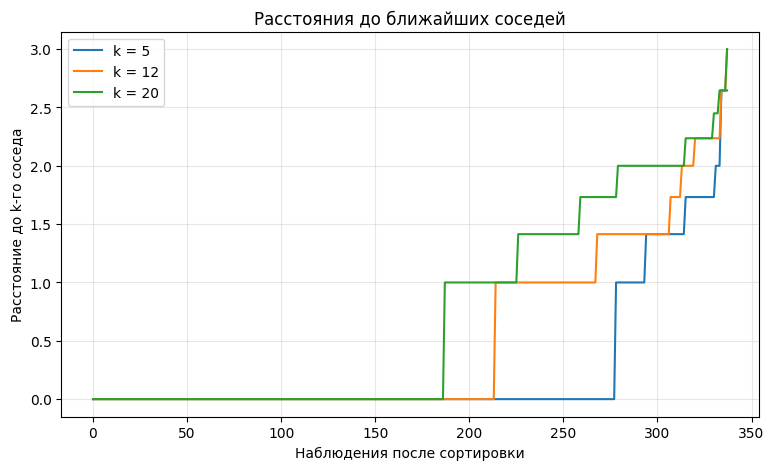

In [9]:
from sklearn.neighbors import NearestNeighbors

plt.figure(figsize=(9, 5))

for k in [5, 12, 20]:
    neighbors = NearestNeighbors(n_neighbors=k, metric='euclidean')
    neighbors.fit(df)

    distances, _ = neighbors.kneighbors(df)
    distances = np.sort(distances[:, -1])

    plt.plot(distances, label=f'k = {k}')

plt.xlabel('Наблюдения после сортировки')
plt.ylabel('Расстояние до k-го соседа')
plt.title('Расстояния до ближайших соседей')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

На графике много нулевых расстояний из-за повторяющихся наблюдений. При увеличении числа соседей расстояния начинают расти раньше.

Наиболее заметный рост наблюдается при расстояниях от 1 до 2. Поэтому для проверки eps рассмотрим значения в этом диапазоне и немного выше.

### 3.2. Проверка параметров

Проверим несколько сочетаний eps и min_samples. Для каждого варианта рассчитаем количество кластеров и шумовых наблюдений.

Количество кластеров заранее не задаем, оно определяется алгоритмом DBSCAN.

In [10]:
from sklearn.cluster import DBSCAN

results = []

for eps in [1, 1.4, 1.8, 2, 2.2, 2.5]:
    for m in [5, 8, 12, 20]:
        labels = DBSCAN(eps=eps, min_samples=m).fit_predict(df)

        n_clusters = len(set(labels) - {-1})
        n_noise = sum(labels == -1)

        results.append([eps, m, n_clusters, n_noise])

res = pd.DataFrame(
    results,
    columns=['eps', 'min_samples', 'Кластеры', 'Шум']
)

res

,eps,min_samples,Кластеры,Шум
0,1.0,5,9,44
1,1.0,8,8,50
2,1.0,12,6,69
3,1.0,20,4,100
4,1.4,5,9,44
5,1.4,8,8,50
6,1.4,12,6,69
7,1.4,20,4,100
8,1.8,5,4,6
9,1.8,8,4,10


При увеличении eps количество кластеров уменьшается. Одновременно сокращается число шумовых наблюдений.

При eps = 1,8 выделяется 4–5 кластеров с небольшим количеством шума. При eps = 2 количество кластеров уменьшается до 3.

Для дальнейшего анализа рассмотрим eps = 1,8 и проверим качество кластеризации.


### 3.3. Влияние параметров на результат

Построим графики зависимости числа кластеров и доли шумовых наблюдений от eps при разных значениях min_samples.

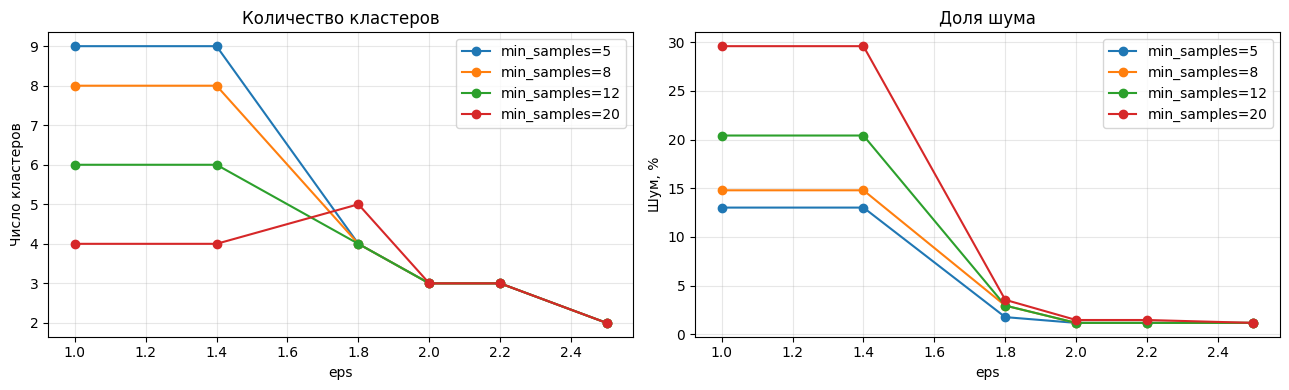

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for m in [5, 8, 12, 20]:
    t = res[res['min_samples'] == m]

    axes[0].plot(t['eps'], t['Кластеры'], 'o-', label=f'min_samples={m}')
    axes[1].plot(t['eps'], t['Шум'] / len(df) * 100, 'o-', label=f'min_samples={m}')

axes[0].set_title('Количество кластеров')
axes[0].set_xlabel('eps')
axes[0].set_ylabel('Число кластеров')

axes[1].set_title('Доля шума')
axes[1].set_xlabel('eps')
axes[1].set_ylabel('Шум, %')

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

При увеличении eps число кластеров и доля шума уменьшаются. Наиболее заметные изменения происходят между eps = 1,4 и eps = 1,8.

При eps = 1,8 получаем 4 кластера для min_samples от 5 до 12. Доля шума при этом составляет 1,8–3%. При eps = 2 число кластеров уменьшается до 3.

Таким образом, eps = 1,8 позволяет выделить больше отдельных групп при небольшой доле шума.

### 3.4. Тепловая карта параметров

Построим тепловую карту числа кластеров для разных значений eps и min_samples. Это позволит оценить устойчивость разбиения при изменении параметров.

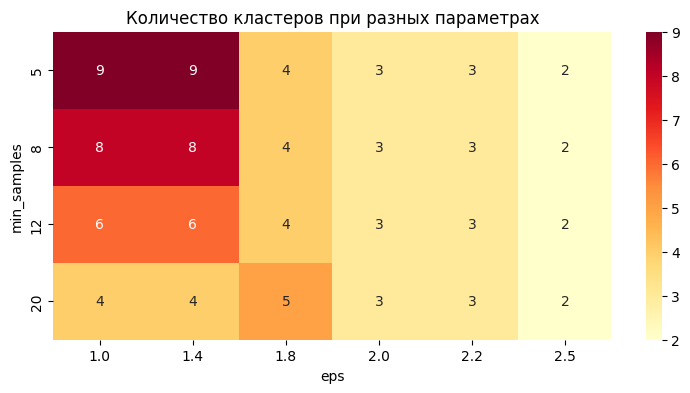

In [12]:
table = res.pivot(index='min_samples', columns='eps', values='Кластеры')

plt.figure(figsize=(9, 4))
sns.heatmap(table, annot=True, fmt='.0f', cmap='YlOrRd')

plt.title('Количество кластеров при разных параметрах')
plt.xlabel('eps')
plt.ylabel('min_samples')
plt.show()

При eps = 1,8 выделяется 4 кластера для min_samples = 5, 8 и 12. При min_samples = 20 количество кластеров увеличивается до 5.

При eps = 2–2,2 все проверенные значения min_samples дают 3 кластера. Таким образом, результат при eps = 1,8 достаточно устойчив к изменению min_samples в диапазоне от 5 до 12.

### 3.5. Оценка качества кластеризации

Для оценки разделения кластеров рассчитаем коэффициент силуэта при разных eps и min_samples. Шумовые наблюдения исключим из расчета.

Чем ближе коэффициент к 1, тем лучше разделены кластеры.

In [13]:
from sklearn.metrics import silhouette_score

results = []

for eps in [1, 1.4, 1.8, 2, 2.2, 2.5]:
    for m in [5, 8, 12, 20]:
        labels = DBSCAN(eps=eps, min_samples=m).fit_predict(df)

        mask = labels != -1
        n_clusters = len(set(labels) - {-1})

        if 2 <= n_clusters < sum(mask):
            score = silhouette_score(df[mask], labels[mask])
        else:
            score = np.nan

        results.append([eps, m, n_clusters, sum(~mask), score])

scores = pd.DataFrame(
    results,
    columns=['eps', 'min_samples', 'Кластеры', 'Шум', 'Силуэт']
)

scores.round(3)

,eps,min_samples,Кластеры,Шум,Силуэт
0,1.0,5,9,44,0.898
1,1.0,8,8,50,0.896
2,1.0,12,6,69,0.905
3,1.0,20,4,100,0.911
4,1.4,5,9,44,0.898
5,1.4,8,8,50,0.896
6,1.4,12,6,69,0.905
7,1.4,20,4,100,0.911
8,1.8,5,4,6,0.737
9,1.8,8,4,10,0.745


Максимальный коэффициент силуэта составляет 0,911, но при этом 100 наблюдений отнесены к шуму.

При eps = 1,8 и min_samples = 12 коэффициент силуэта равен 0,745, выделено 4 кластера и 10 шумовых точек. Этот вариант сохраняет большую часть наблюдений при достаточно хорошем разделении кластеров.

### 3.6. Выбор параметров DBSCAN

Для дальнейшей кластеризации выбраны eps = 1,8 и min_samples = 12. Значение min_samples выбрано с учетом 11 признаков и проверено при разных параметрах.

При выбранных значениях получено 4 кластера и 10 шумовых наблюдений (2,96%). Коэффициент силуэта составил 0,745.

Такое сочетание параметров обеспечивает хорошее разделение кластеров при небольшой доле шума.

## 4. Кластеризация методом DBSCAN

### 4.1. Проведение кластеризации

Проведем кластеризацию с параметрами eps = 1,8 и min_samples = 12. Определим количество наблюдений в каждом кластере и число шумовых точек.

In [14]:
db = DBSCAN(eps=1.8, min_samples=12)
labels = db.fit_predict(df)

df_db = df.copy()
df_db['Кластер'] = labels

counts = df_db['Кластер'].value_counts().sort_index()
counts

,count
Кластер,
-1,10
0,110
1,100
2,61
3,57


### 4.2. Распределение размеров кластеров

Построим столбчатую диаграмму размеров кластеров. Шумовые наблюдения покажем отдельно.

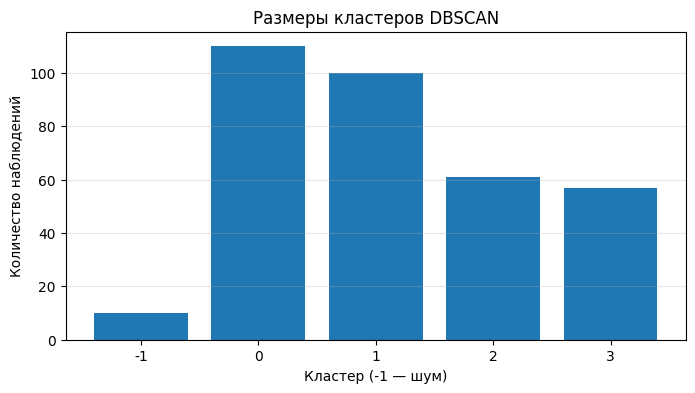

In [15]:
plt.figure(figsize=(8, 4))

plt.bar(counts.index.astype(str), counts.values)

plt.xlabel('Кластер (-1 — шум)')
plt.ylabel('Количество наблюдений')
plt.title('Размеры кластеров DBSCAN')
plt.grid(axis='y', alpha=0.3)
plt.show()

### 4.3. Визуализация кластеров методом PCA

Используем метод главных компонент (PCA) для отображения кластеров на плоскости. Размер точек будет зависеть от количества одинаковых наблюдений, цвет — от номера кластера. Шум выделим черным.

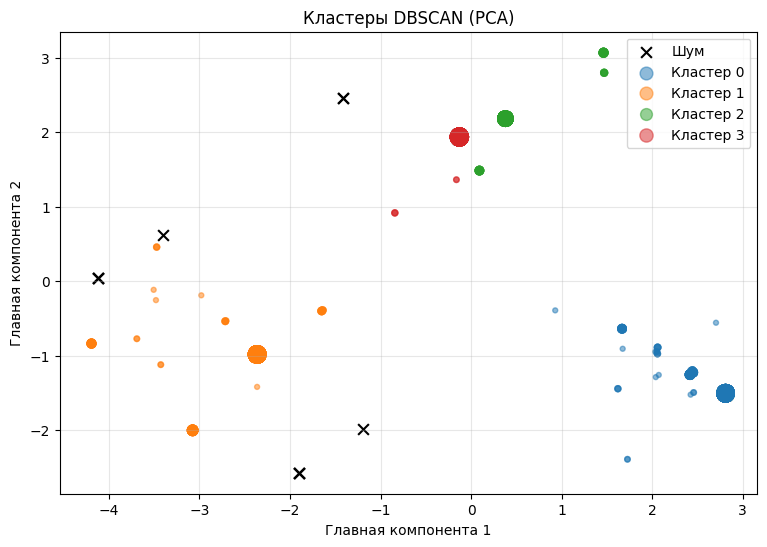

Объясненная дисперсия: 77.98 %


In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
xy = pca.fit_transform(df)

sizes = df.groupby(list(df.columns))[df.columns[0]].transform('size')

plt.figure(figsize=(9, 6))

for i in sorted(set(labels)):
    mask = labels == i

    if i == -1:
        plt.scatter(xy[mask, 0], xy[mask, 1],
                    c='black', marker='x', s=60, label='Шум')
    else:
        plt.scatter(xy[mask, 0], xy[mask, 1],
                    s=10 + sizes[mask] * 3,
                    alpha=0.5, label=f'Кластер {i}')

plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.title('Кластеры DBSCAN (PCA)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Объясненная дисперсия:',
      round(sum(pca.explained_variance_ratio_) * 100, 2), '%')

На графике PCA выделяются 4 группы наблюдений. Кластеры 0 и 1 расположены по разные стороны первой главной компоненты, а кластеры 2 и 3 различаются преимущественно по второй.

Крупные точки соответствуют часто повторяющимся наборам оценок. Шумовые наблюдения расположены отдельно от основных групп.

Две главные компоненты объясняют 77,98% дисперсии данных.

### 4.4. Сравнение результатов при разных eps

Сравним результаты кластеризации при eps = 1,8 и eps = 2,0 с одинаковым min_samples = 12.

Для обоих вариантов используем одни и те же координаты PCA. Это позволит увидеть изменение границ кластеров и количества шумовых точек.

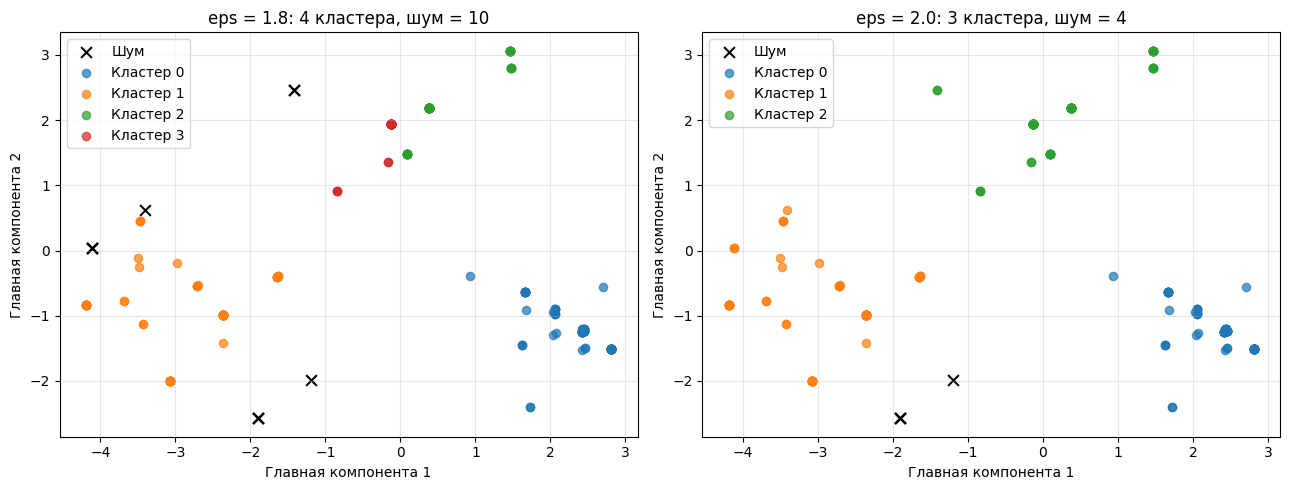

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, eps in zip(axes, [1.8, 2.0]):
    labels_var = DBSCAN(eps=eps, min_samples=12).fit_predict(df)

    for i in sorted(set(labels_var)):
        mask = labels_var == i

        if i == -1:
            ax.scatter(xy[mask, 0], xy[mask, 1],
                       c='black', marker='x', s=60, label='Шум')
        else:
            ax.scatter(xy[mask, 0], xy[mask, 1],
                       s=35, alpha=0.7, label=f'Кластер {i}')

    n_clusters = len(set(labels_var) - {-1})
    n_noise = sum(labels_var == -1)

    ax.set_title(f'eps = {eps}: {n_clusters} кластера, шум = {n_noise}')
    ax.set_xlabel('Главная компонента 1')
    ax.set_ylabel('Главная компонента 2')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

При увеличении eps с 1,8 до 2,0 количество кластеров уменьшается с 4 до 3. Два кластера объединяются, а число шумовых точек сокращается с 10 до 4.

При eps = 1,8 сохраняется более подробное разделение данных, поэтому оставляем этот вариант для дальнейшего анализа.

## 5. Анализ полученных кластеров

### 5.1. Средние значения признаков

Рассчитаем средние значения V1–V11 для каждого кластера. Шумовые наблюдения исключим из расчета.

In [18]:
means = df_db[df_db['Кластер'] != -1].groupby('Кластер').mean()

means.round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Кластер,,,,,,,,,,,
0,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
1,2.89,2.82,2.75,2.59,2.66,2.63,2.73,2.87,4.95,4.82,4.87
2,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75
3,3.00,3.00,3.00,2.95,2.95,2.95,4.91,4.91,3.00,3.00,3.00


Кластеры различаются по средним оценкам признаков:

- Кластер 0 — высокие оценки V1–V4 (4,68–4,85).
- Кластер 1 — высокие оценки V9–V11 (4,82–4,95).
- Кластер 2 — высокие оценки V5 и V6 (4,85).
- Кластер 3 — высокие оценки V7 и V8 (4,91).

Остальные оценки в основном находятся около 3. У каждого кластера выделяется своя группа признаков.

### 5.2. Тепловая карта средних значений

Построим тепловую карту средних оценок V1–V11 по кластерам. Цветом выделим различия между группами.

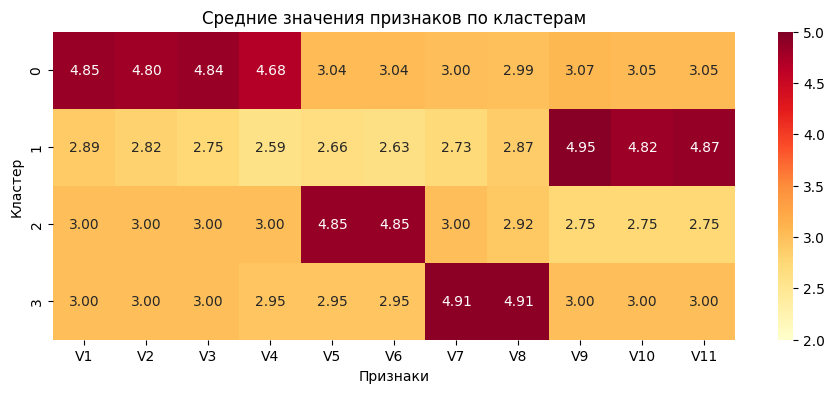

In [19]:
plt.figure(figsize=(11, 4))

sns.heatmap(means, annot=True, fmt='.2f',
            cmap='YlOrRd', vmin=2, vmax=5)

plt.title('Средние значения признаков по кластерам')
plt.xlabel('Признаки')
plt.ylabel('Кластер')
plt.show()

На тепловой карте видно, что каждый кластер имеет свою группу признаков с высокими оценками: V1–V4, V9–V11, V5–V6 и V7–V8.

Средние значения остальных признаков в основном находятся около 3. Кластеры хорошо различаются по своим характеристикам.

### 5.3. Анализ шумовых наблюдений

Рассмотрим значения признаков у шумовых наблюдений. Сравним их с основными кластерами, чтобы определить причины их выделения в шум.

In [20]:
noise = df_db[df_db['Кластер'] == -1]

noise

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,Кластер
112,2,4,4,4,2,2,2,3,5,5,5,-1
139,2,4,4,4,2,2,2,3,5,5,5,-1
177,2,4,4,4,2,2,2,3,5,4,4,-1
184,2,2,2,2,2,2,4,4,5,5,5,-1
185,2,2,2,2,2,2,4,4,5,5,5,-1
188,2,4,4,4,2,2,2,3,5,5,5,-1
190,2,2,2,2,2,2,4,4,5,4,4,-1
204,2,2,2,2,2,2,4,4,5,5,5,-1
308,3,2,2,2,2,3,5,5,3,3,3,-1
324,3,2,2,2,2,3,5,5,3,3,3,-1


К шуму отнесено 10 наблюдений. Среди них встречаются повторяющиеся наборы оценок.

Часть наблюдений сочетает высокие оценки V9–V11 с V2–V4 или V7–V8. Другие имеют высокие оценки V7–V8 при низких значениях V2–V5.

Такие сочетания отличаются от основных профилей кластеров. При выбранных параметрах DBSCAN эти точки не вошли ни в одну плотную группу.

## 6. Сравнение DBSCAN и K-means

В предыдущей лабораторной методом K-means было выделено 4 кластера.

Для сравнения двух разбиений используем скорректированный индекс Рэнда (ARI). Он оценивает совпадение распределения наблюдений по кластерам независимо от их номеров.

Шумовые точки DBSCAN исключим из сравнения.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_km = km.fit_predict(df)

mask = labels != -1

ari = adjusted_rand_score(labels_km[mask], labels[mask])

print('ARI:', round(ari, 4))

ARI: 1.0


## 7. Вывод

В работе проведена кластеризация набора данных «Леденцы» методом DBSCAN. Предварительно выполнен разведочный анализ данных (EDA). Из 338 наблюдений найдено 45 уникальных наборов оценок, остальные строки являются повторениями.

Для кластеризации выбраны параметры eps = 1,8 и min_samples = 12. Получено 4 кластера и 10 шумовых наблюдений (2,96%).

Кластеры различаются по преобладающим признакам:

- **Кластер 0 (110 наблюдений)** - V1–V4;
- **Кластер 1 (100 наблюдений)** — V9–V11;
- **Кластер 2 (61 наблюдение)** — V5–V6;
- **Кластер 3 (57 наблюдений)** — V7–V8.

Коэффициент силуэта составил 0,745, что указывает на хорошее разделение кластеров. Две главные компоненты PCA объясняют 77,98% дисперсии данных.

При сравнении с K-means получен ARI = 1,0. Это означает полное совпадение разбиений для 328 наблюдений, не отнесенных к шуму.

Таким образом, DBSCAN позволил выделить четыре группы потребителей с разными оценками признаков и определить 10 шумовых наблюдений.
